## 1. Setup: libraries import

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. CSV load and dataset


In [ ]:
df = pd.read_csv("/content/sample_data/sales_visualization_dataset.csv")
df["Date"] = pd.to_datetime(df["Date"])

display(df.head())
print("Shape:", df.shape)
df.info()

,Order_ID,Date,Product,Category,Region,Units_Sold,Unit_Price_BDT,Revenue_BDT,Discount,Customer_Rating,Payment_Method
0,O001,2026-01-01,Laptop,Electronics,North,2,65000,130000,0.05,4.7,Card
1,O002,2026-01-02,Headphones,Electronics,South,5,2500,12500,0.10,4.2,Cash
2,O003,2026-01-03,Office Chair,Furniture,East,3,8500,25500,0.00,4.5,Mobile Banking
3,O004,2026-01-04,Notebook,Stationery,West,20,80,1600,0.05,4.0,Cash
4,O005,2026-01-05,Desk,Furniture,North,2,12000,24000,0.10,4.3,Card


Shape: (20, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         20 non-null     object        
 1   Date             20 non-null     datetime64[ns]
 2   Product          20 non-null     object        
 3   Category         20 non-null     object        
 4   Region           20 non-null     object        
 5   Units_Sold       20 non-null     int64         
 6   Unit_Price_BDT   20 non-null     int64         
 7   Revenue_BDT      20 non-null     int64         
 8   Discount         20 non-null     float64       
 9   Customer_Rating  20 non-null     float64       
 10  Payment_Method   20 non-null     object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 1.8+ KB


## 3. Numeric ও categorical columns


In [ ]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numeric:", numeric_cols)
print("Categorical:", categorical_cols)
display(df.describe())

Numeric: ['Units_Sold', 'Unit_Price_BDT', 'Revenue_BDT', 'Discount', 'Customer_Rating']
Categorical: ['Order_ID', 'Product', 'Category', 'Region', 'Payment_Method']


,Date,Units_Sold,Unit_Price_BDT,Revenue_BDT,Discount,Customer_Rating
count,20,20.000000,20.000000,20.000000,20.000000,20.000000
mean,2026-01-10 12:00:00,6.000000,10874.500000,22624.000000,0.047500,4.265000
min,2026-01-01 00:00:00,1.000000,60.000000,1080.000000,0.000000,3.700000
25%,2026-01-05 18:00:00,2.000000,725.000000,4912.500000,0.000000,4.075000
50%,2026-01-10 12:00:00,3.500000,2350.000000,9850.000000,0.050000,4.250000
75%,2026-01-15 06:00:00,7.250000,14625.000000,26375.000000,0.100000,4.500000
max,2026-01-20 00:00:00,20.000000,65000.000000,130000.000000,0.100000,4.800000
std,NaN,5.749142,16080.492423,30984.439117,0.041279,0.301357


## 4. Matplotlib — Scatter Plot


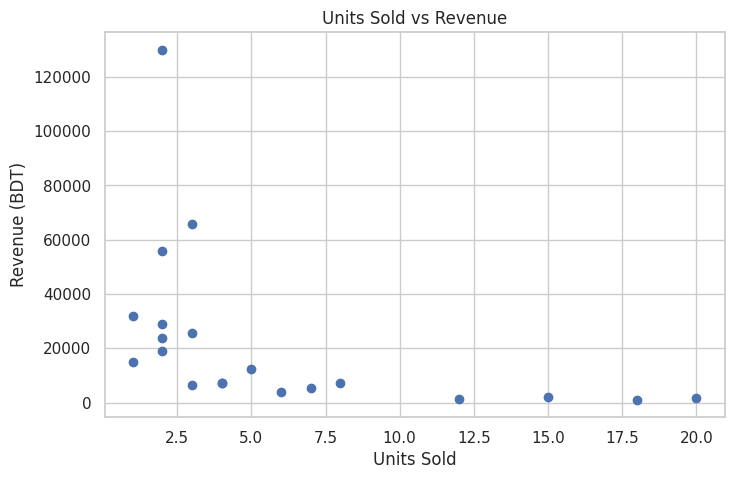

In [ ]:
#scatterplot

plt.scatter(
    df["Units_Sold"],
    df["Revenue_BDT"]
)

plt.title("Units Sold vs Revenue")
plt.xlabel("Units Sold")
plt.ylabel("Revenue (BDT)")

plt.show()

## 5. Matplotlib — Histogram


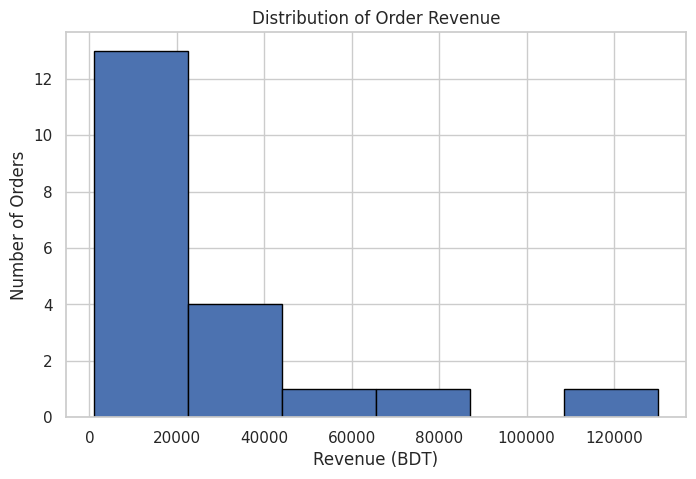

In [ ]:
#plt.hist

plt.hist(
    df["Revenue_BDT"],
    bins = 6,
    edgecolor = "black"
)

plt.title("Distribution of Order Revenue")
plt.xlabel("Revenue (BDT)")
plt.ylabel("Number of Orders")
plt.show()

## 6. Matplotlib — Bar Chart


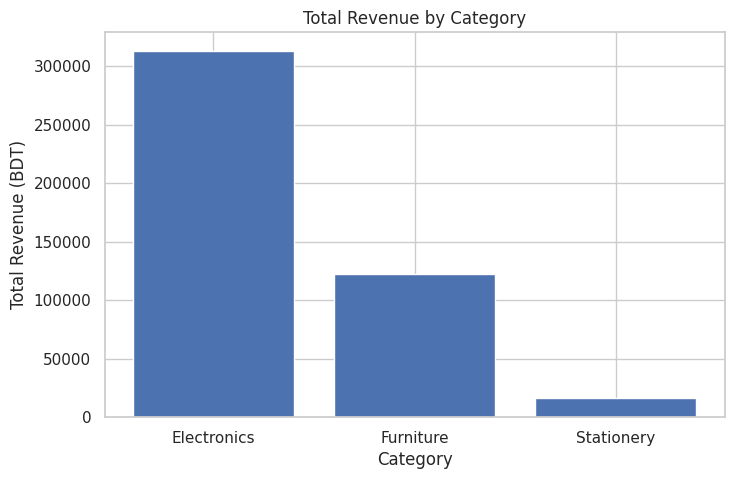

In [ ]:
category_revenue = df.groupby("Category")["Revenue_BDT"].sum()
plt.bar(category_revenue.index , category_revenue.values)

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue (BDT)")
plt.show()

## 7. Matplotlib — Pie Chart


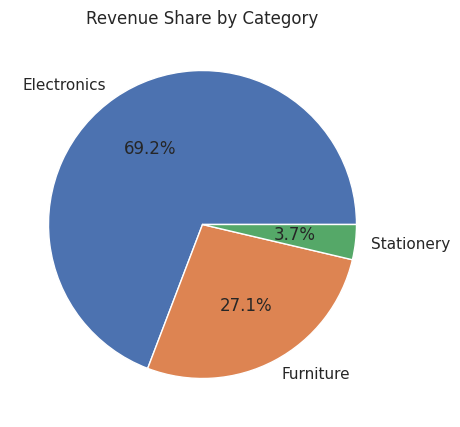

In [ ]:
#plt.pie

plt.pie(
    category_revenue.values ,
    labels = category_revenue.index,
    autopct = "%1.1f%%"
)

plt.title("Revenue Share by Category")
plt.show()

## 8. Seaborn — Line Plot

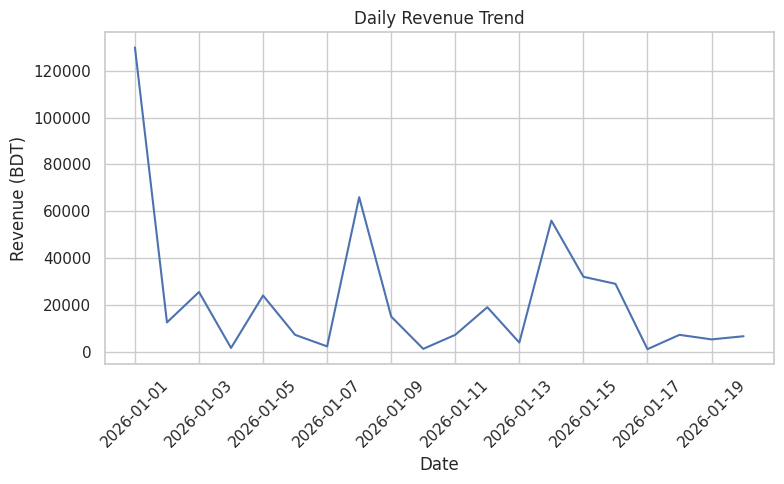

In [ ]:
daily_revenue = df.groupby("Date" , as_index = False)["Revenue_BDT"].sum()

sns.lineplot(
    data = daily_revenue ,
    x = "Date",
    y = "Revenue_BDT"
)


plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (BDT)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Seaborn — Scatter Plot


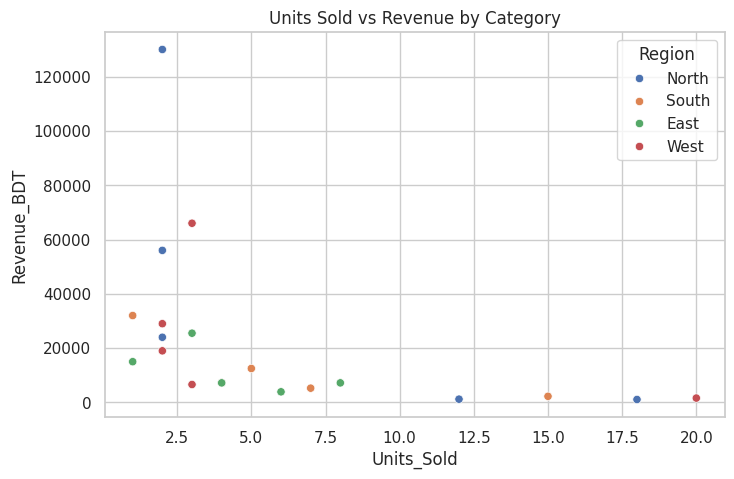

In [ ]:
sns.scatterplot(
    data = df ,
    x = "Units_Sold",
    y = "Revenue_BDT",
    hue = "Region"


)
plt.title("Units Sold vs Revenue by Category")
plt.show()

## 10. Seaborn — Histogram


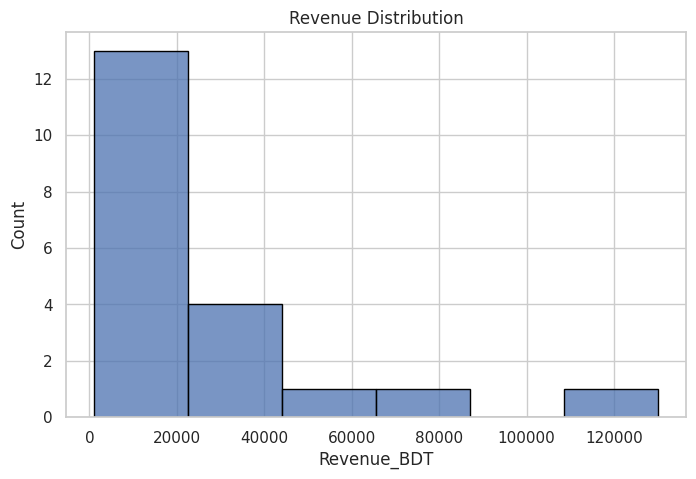

In [ ]:
sns.histplot(
    data = df,
    x = "Revenue_BDT",
    bins = 6,
    edgecolor = "black"
)


plt.title("Revenue Distribution")
plt.show()

## 11. Seaborn — KDE Plot


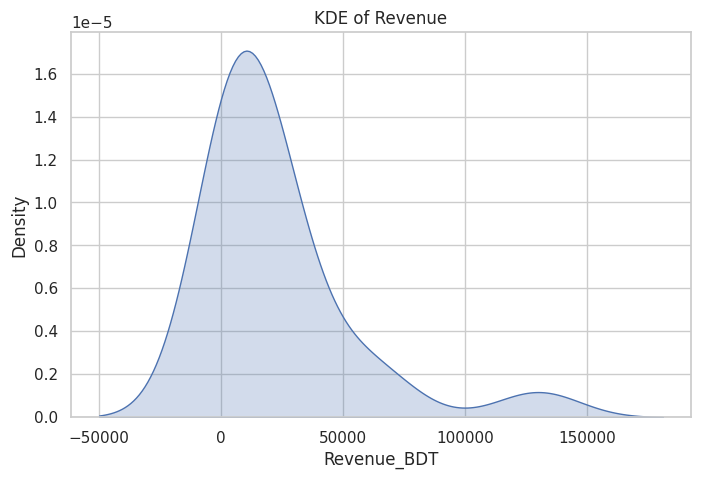

In [ ]:
sns.kdeplot(
    data = df,
    x = "Revenue_BDT",
    fill = True
)


plt.title("KDE of Revenue")
plt.show()

## 12. Seaborn — Count Plot


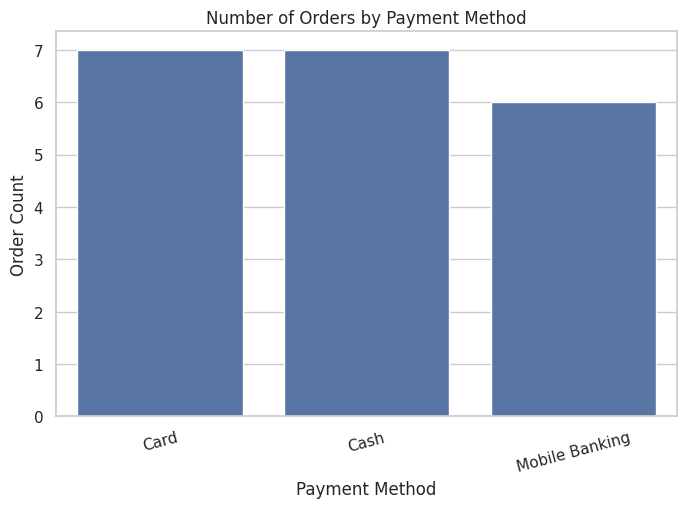

In [ ]:
sns.countplot(
    data = df,
    x ="Payment_Method"
)



plt.title("Number of Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Order Count")
plt.xticks(rotation=15)
plt.show()

## 13. Seaborn — Bar Plot


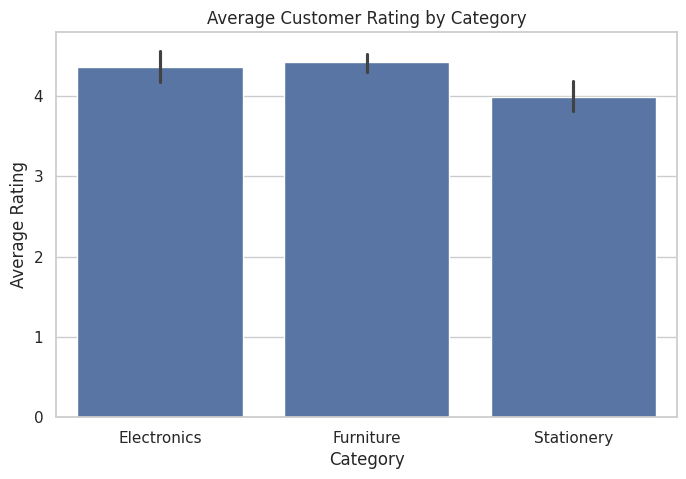

In [ ]:
sns.barplot(
    data = df ,
    x = "Category",
    y = "Customer_Rating"
)


plt.title("Average Customer Rating by Category")
plt.ylabel("Average Rating")
plt.show()

## 14. Seaborn — Facet Plot


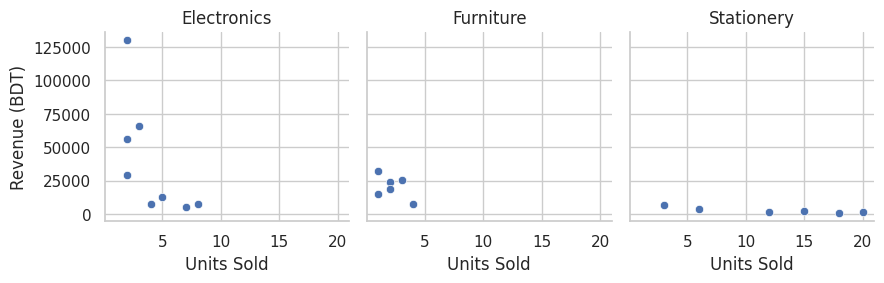

In [ ]:
g = sns.FacetGrid(
    df ,
    col = "Category"
)

g.map_dataframe(
    sns.scatterplot,
    x = "Units_Sold",
    y = "Revenue_BDT"
)




g.set_axis_labels("Units Sold", "Revenue (BDT)")
g.set_titles("{col_name}")
plt.show()

## 15. Seaborn — Pair Plot


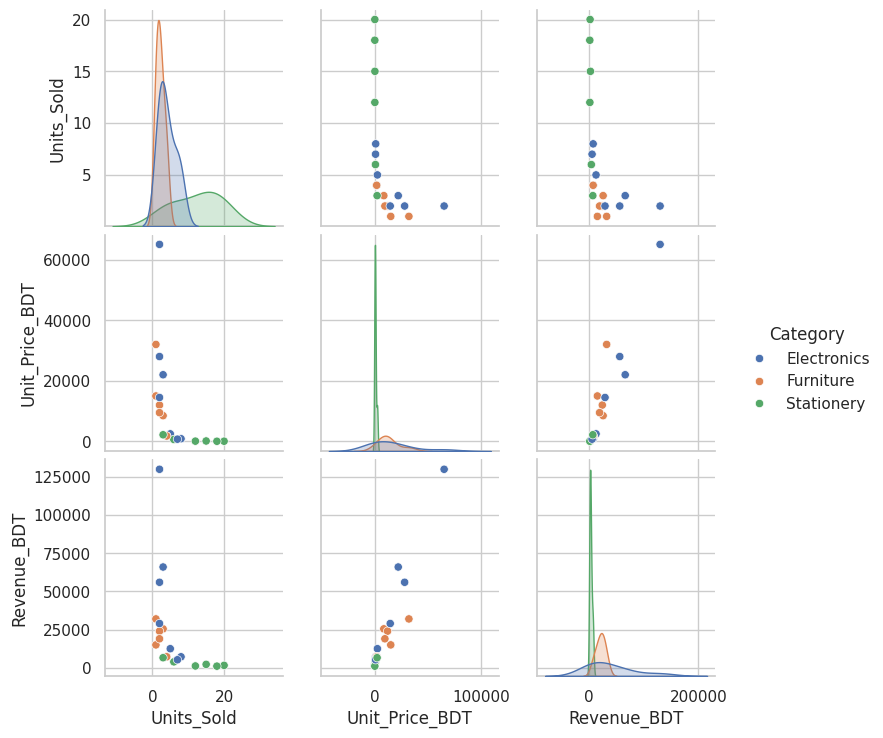

In [ ]:
sns.pairplot(
    df,
    vars = [
        "Units_Sold",
        "Unit_Price_BDT",
        "Revenue_BDT"
    ],
    hue = "Category"



)
plt.show()

##Plotly

In [ ]:
#plotly

%pip install plotly
import plotly.express as px

fig = px.scatter(
    df,
    x="Units_Sold",
    y="Revenue_BDT",
    color="Category",
    hover_data=["Product", "Region"],
    title="Interactive Sales Visualization"
)

fig.show()

## Matplotlib docs: https://matplotlib.org/stable/gallery/
## Seaborn gallery: https://seaborn.pydata.org/examples/